In [507]:
import re
import os
from dataclasses import dataclass
import numpy as np
import torch

@dataclass
class Sweep:
    data: np.ndarray
    time: np.ndarray
    error: np.ndarray
    quality: np.ndarray
    tx_ramp: np.ndarray
    tx_ramp_time: np.ndarray
    current: float
    frequency: float
    is_noise: bool
    field_shift_factor: float
    time_delay: float
    ramp_time: float
    # rx_frontgate: float
    tx_turnontime: float
    ramp_time_on: float
    number: int
    channel: int
    low_pass: np.ndarray
    points: int
    
    @classmethod
    def from_usf_text(cls, txt):
        """parse a sweep block, will return the next sweep"""
        sweep = {}
        sweep_extra = {}
        lines = txt.lower().strip().split('\n')
        lines  = [line.strip() for line in lines]
        i_head = lines.index('/end')
        for line in lines[:i_head]:
            i_colon = line.index(':')
            tmp = line[i_colon+1:]
            key = line[1:i_colon].replace('sweep_', '')
            
            cdict = sweep if key in cls.__dataclass_fields__ else sweep_extra
            if ',' in tmp:
                cdict[key] = np.array([float(x) for x in tmp.split(',')])
            else:
                try:
                    cdict[key] = float(tmp)
                except ValueError:
                    cdict[key] = tmp.strip()

        x = np.genfromtxt(lines[i_head+3:i_head+3+int(sweep['points'])], delimiter=',')#, dtype=(float,float,float,int))
        sweep['time'] = x[:, 0]
        sweep['data'] = x[:, 1]
        sweep['error']= x[:, 2]
        sweep['quality'] = x[:,3].astype(bool)
        tx_time = sweep['tx_ramp'][::2]*1
        tx_ramp = sweep['tx_ramp'][1::2]*1
        sweep['tx_ramp'] = tx_ramp
        sweep['tx_ramp_time'] = tx_time
        self = cls(**sweep)
        for key, value in sweep_extra.items():
            exec(f'self.{key} = value')
        return self
    
    @staticmethod
    def combine_sweeps(sweep_list):
        mega_sweep = {}
        mega_sweep_extra = {}
        for key in vars(sweep_list[0]):
            x = [eval(f'sweep.{key}') for sweep in sweep_list]
            if not isinstance(x, np.ndarray):
                try:
                    x = np.array(x)
                except ValueError:
                    x = np.array([str(xx) for xx in x])

            if key in Sweep.__dataclass_fields__:
                mega_sweep[key] = x
            else:
                mega_sweep_extra[key] = x
        csweep = Sweep(**mega_sweep)
        for key, value in mega_sweep_extra.items():
            exec(f'csweep.{key} = value')
        return csweep
    
    @classmethod
    def from_usf(cls, fname, combine=True):
        with open(fname, 'rb') as f:
            sweep = cls.from_buffer(f, combine=combine)
        return sweep

    @classmethod
    def from_buffer(cls, f, combine=True):
        """parse a usf file, will return """
        #with open(fname, 'r') as f:

        txt = f.read().decode('utf-8')
        
        header = txt[txt.index('/DATE:'):txt.index('/VOLTAGE_UNITS:')].replace('//END', '')
        sweeps = []
        count = 0
        while '/SWEEP_NUMBER' in txt:
            i = txt.index('/SWEEP_NUMBER:')
            sweeps.append(Sweep.from_usf_text(header+txt[i:]))
            txt = txt[i+1:]

        if combine:
            points = set([x.points for x in sweeps])
            mega_sweeps = []
            for pnts in points:
                mega_sweeps.append(cls.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
            return mega_sweeps
        else:
            return sweeps
    
    def flip_sign(self):
        self.data *= -1


    def get_polarity(self, gates=slice(4)):
        return np.sign(self.data[gates].mean())
    
    def correct_polarity(self, **kwargs):
        self.data *= self.get_polarity(**kwargs)        

from anemone.forwards import Forward, logify_forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

def sweep2fwr(sweeps, fwr=Forward, leadin_length=None):
    points = sorted(set(swp.points for swp in sweeps))
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        if leadin_length is None:
            rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        else:
            rx = Receiver(x=3.+leadin_length+3.+0.4)
        wv = Waveform(swp.tx_ramp_time, swp.tx_ramp)
        filter_chain = []
        for f_cut, order in zip(swp.low_pass[::2], swp.low_pass[1::2]):
            filter_chain.append(ButterworthFilter(f_cut, order))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6, do_setup=False))
    return forwards

In [736]:
lm,hm = Sweep.from_usf("C:/Users/au646858/geophysics_data/TEM/alaska_ip/tesh60hz/Data/USF_Files_tesh60hz/L001_S006_2026_0504_220914.usf")

In [737]:
fwrs = sweep2fwr(Sweep.from_usf("C:/Users/au646858/geophysics_data/TEM/alaska_ip/tesh60hz/Data/USF_Files_tesh60hz/L001_S006_2026_0504_220914.usf", combine=False), leadin_length=9.)

In [738]:
dmfwr = fwrs[0]+fwrs[1]

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\forwards\forwards.py:738: ComplexWarning: Casting complex values to real discards the imaginary part
  H2t[i_t, i_g] = t1[full_mask].flatten()


In [739]:
dmfwr.receiver

Receiver(x=tensor(15.4000, dtype=torch.float64), y=tensor(0., dtype=torch.float64), z=tensor(0., dtype=torch.float64), grid=False, weighting=None)

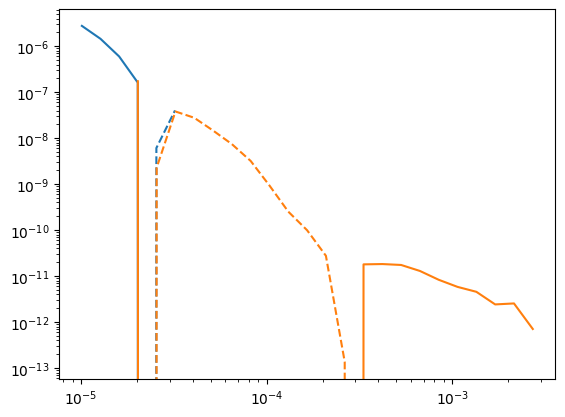

In [740]:
plt.figure()
plt.loglog(lm.time.mean(0), lm.data.mean(0))
plt.loglog(lm.time.mean(0),-lm.data.mean(0), 'C0--')
plt.loglog(hm.time.mean(0), hm.data.mean(0))
plt.loglog(hm.time.mean(0),-hm.data.mean(0), 'C1--')

In [741]:
d_obs_lm = np.average(lm.data, axis=0)#, weights=(1./lm.error)**2)
d_obs_hm = np.average(hm.data, axis=0)#, weights=(1./hm.error)**2)

d_abserr = np.abs(np.concatenate([(lm.data*lm.error).mean(0), (hm.data*hm.error).mean(0)]))/100.

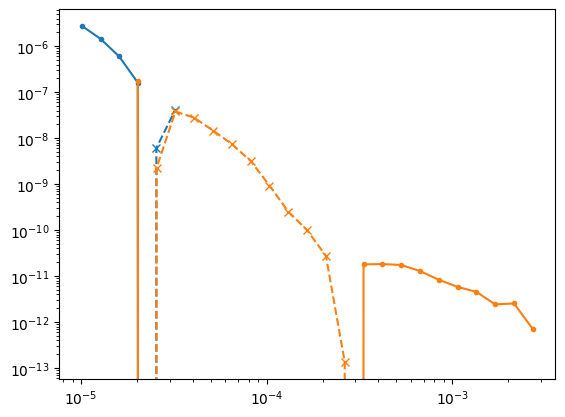

In [742]:
plt.figure()
plt.loglog(lm.time.mean(0), lm.data.mean(0))
plt.loglog(lm.time.mean(0),-lm.data.mean(0), 'C0--')

plt.loglog(lm.time.mean(0), d_obs_lm, 'C0.')
plt.loglog(lm.time.mean(0),-d_obs_lm, 'C0x')


plt.loglog(hm.time.mean(0), hm.data.mean(0))
plt.loglog(hm.time.mean(0),-hm.data.mean(0), 'C1--')
plt.loglog(hm.time.mean(0), d_obs_hm, 'C1.')
plt.loglog(hm.time.mean(0),-d_obs_hm, 'C1x')

In [743]:
d_obs = np.concatenate([d_obs_lm, d_obs_hm])
d_relerr = np.concatenate([lm.error.mean(0), hm.error.mean(0)])/100
d_abserr = np.abs(d_obs)*d_relerr

In [744]:
rho = torch.ones(31)*40.
thick = torch.logspace(0,1,30)#.cumsum(0)
dmfwr.kind='res'
d_pred = dmfwr(rho, thick)

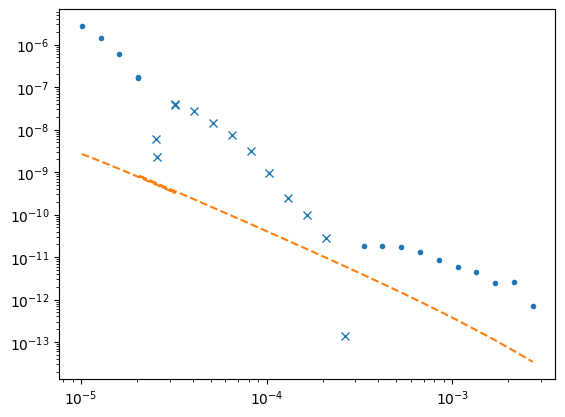

In [745]:
plt.figure()
plt.loglog(dmfwr.times,  d_obs, 'C0.')
plt.loglog(dmfwr.times, -d_obs, 'C0x')
plt.loglog(dmfwr.times, d_pred.detach().numpy(), 'C1--')

In [746]:
dmfwr.kind='colecole'

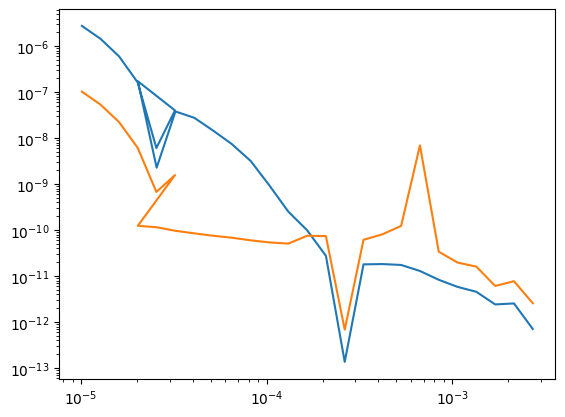

In [748]:
plt.figure()
plt.loglog(dmfwr.times, np.abs(d_obs))
plt.loglog(dmfwr.times, d_abserr)

In [782]:
def modelize(mvec):
    mt = torch.from_numpy(mvec).exp()
    nlay = len(mt)//4
    rho,m,tau,c = mt[:nlay], mt[nlay:2*nlay], mt[2*nlay:3*nlay], mt[3*nlay:]
    return rho, m, tau, c, thick
    
def objective(mvec):
    rho, m, tau, c, thick = modelize(mvec)
    d_pred = -1*dmfwr(rho, m, tau, c, thick).numpy()
    d_misfit = (d_obs-d_pred)/d_abserr
    d_mod = torch.concatenate([rho.log().diff(), m.log().diff(), tau.log().diff(), c.log().diff()]).numpy() / np.log1p(0.1)
    return np.concatenate([d_misfit, d_mod])**2

from scipy import optimize

from anemone.physics import drte_dsigma

nlay = len(rho)

d_mod_jac = np.zeros((nlay*4, nlay*4))
keep = np.ones(nlay*4, dtype=bool)
for i in range(4):
    for j in range(nlay-1):
        idx = slice(i*nlay+j, i*nlay+j+2)
        d_mod_jac[len(d_obs)+j, idx] = np.array([-1, 1]) / np.log1p(0.1)
    keep[i*nlay] = False
d_mod_jac = d_mod_jac[keep, :]

def jacobian(mvec):
    rho,m,tau,c,thick = modelize(mvec)
    _ = dmfwr(rho, m, tau, c, thick)
    mnorm = np.exp(mvec)

    drds = drte_dsigma(dmfwr.sigma, dmfwr.thick, dmfwr.omega, dmfwr.lamda)
    drdrho = -drds / rho[None,:]**2
    w = dmfwr.omega
    iwtp1 = 1+1j*w[:,None]*tau[None,:]
    drhodm =  rho*(1-iwtp1**(-c[None,:]))
    drhodt = -c*rho[None,:]*m[None,:]*(iwtp1**(-c-1))*(1j*w[:,None])
    drhodc = -rho[None,:]*m[None,:]*torch.log(iwtp1)*(iwtp1**(-c[None,:]))    
    Gana =  torch.pi*4e-7*dmfwr.H2t.real @ torch.concatenate([drdrho, drdrho*drhodm, drdrho*drhodt, drdrho*drhodc], dim=1).real
    d_misfit_jac = Gana / d_abserr[:, None]
    d_misfit_jac *= mnorm[None, :]
    return np.concatenate([d_misfit_jac.numpy(), d_mod_jac])

o31  = torch.ones(31, dtype=torch.float64)

from scipy.optimize import least_squares, leastsq
res = least_squares(objective, torch.concatenate([o31*5., o31*1e-6, o31*1e-4, o31*2]).log().numpy(),
                    jac=jacobian, verbose=2)

C:\Users\au646858\AppData\Local\Temp\ipykernel_14056\1228374212.py:42: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d_misfit_jac = Gana / d_abserr[:, None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_14056\1228374212.py:43: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d_misfit_jac *= mnorm[None, :]


   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         1.9933e+12                                    9.40e+06    
       1              5         1.8247e+12      1.69e+11       1.45e+00       2.82e+07    
       2              6         1.5292e+12      2.95e+11       2.91e+00       1.53e+08    
       3              8         1.3696e+12      1.60e+11       1.45e+00       7.74e+07    
       4             10         1.1781e+12      1.91e+11       7.26e-01       5.55e+07    
       5             12         1.1185e+12      5.96e+10       3.63e-01       5.02e+07    
       6             13         1.0308e+12      8.77e+10       7.26e-01       3.54e+07    
       7             14         9.1861e+11      1.12e+11       1.45e+00       4.22e+07    
       8             26         9.1861e+11      0.00e+00       0.00e+00       4.22e+07    
`xtol` termination condition is satisfied.
Function evaluations 26, initial cost 1.9933e+1

In [783]:
d_pred = dmfwr(*modelize(res.x)).detach().numpy()

In [784]:
t_err = np.repeat(dmfwr.times.numpy(), 4)
d_obserr = np.repeat(d_obs, 4)

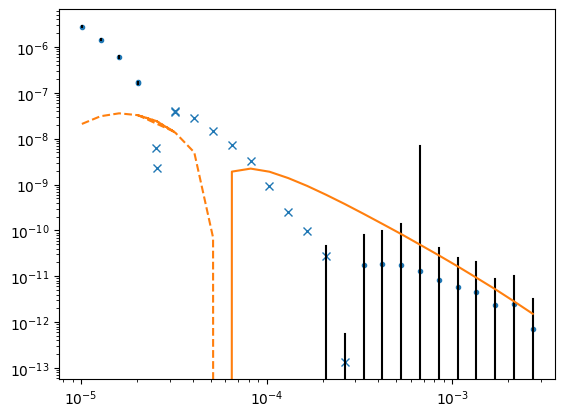

In [785]:
d_obserr[::4] = np.nan
d_obserr[1::4] *= 1.+d_relerr
d_obserr[2::4] *= 1.-d_relerr
d_obserr[3::4] = np.nan


plt.figure()
plt.loglog(dmfwr.times,  d_obs, 'C0.')
plt.loglog(dmfwr.times, -d_obs, 'C0x')
plt.loglog(t_err, d_obserr, 'k-')

plt.loglog(dmfwr.times, d_pred, 'C1-')
plt.loglog(dmfwr.times, -d_pred, 'C1--')

In [759]:
from anemone.inversion import ColeCole
values = [res.x[:nlay], res.x[nlay:2*nlay], res.x[2*nlay:3*nlay], res.x[3*nlay:4*nlay]]
values = [torch.from_numpy(x).exp() if i<100 else torch.from_numpy(x) for i,x in enumerate(values)]
coley  = ColeCole.smooth(values, thick.cumsum(0))

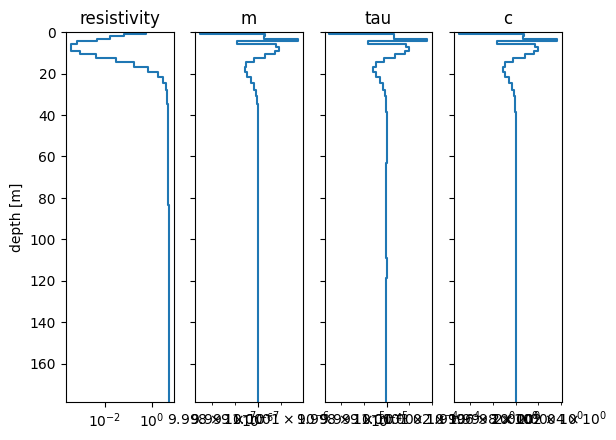

In [781]:
axs = coley.plot()
for ax in axs: ax.set_xscale('log')